<a href="https://colab.research.google.com/github/muhammadabdullahz/vector-autoregressions-VAR-SW/blob/main/notebooks/vector_autoregressions_SW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Overview

This independent replication project examines how vector autoregressions (VARs) capture the dynamic relationships between inflation, unemployment, and monetary policy in the United States. Following Stock and Watson (2001), *Vector Autoregressions*, it uses quarterly U.S. data from 1960Q1 to 2000Q4 to estimate a VAR(4) and investigate how these variables interact over time.

The analysis examines the predictive content of lagged variables, decomposes forecast uncertainty into contributions from different shocks, and traces the effects of unexpected monetary policy shocks through impulse response functions (IRFs). It applies Granger causality tests, forecast error variance decomposition (FEVD), and impulse response analysis.

A central focus is structural identification. The project compares recursive identification using a Cholesky decomposition with structural VAR specifications based on alternative backward-looking and forward-looking Taylor rules. Monte Carlo simulations assess uncertainty around the estimated impulse responses.

### Loading Data

This code loads the Stock and Watson quarterly macroeconomic dataset from Google Drive, cleans the column names, converts the dates into quarterly periods, and creates a DataFrame containing inflation, unemployment, and the federal funds rate.

It then checks that the dataset has 164 complete, unique, chronologically ordered observations from 1960Q1 to 2000Q4, and displays summary statistics for the three variables.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

path = "/content/drive/MyDrive/Stock_Watson_VAR/SW2001_Data.xlsx"
raw = pd.read_excel(path, header=None)

# Rows 0-1 are headers, data starts at row 2. Column 0 is the date.
df = raw.iloc[2:, :4].copy()
df.columns = ["date", "inflation", "unemployment", "fedfunds"]
df.index = pd.PeriodIndex(df["date"].str.upper(), freq="Q")   # "1960q1" -> 1960Q1
df = df.drop(columns="date").astype(float)

print(df.head())
print(df.tail())
print("Observations:", len(df))

Mounted at /content/drive
        inflation  unemployment  fedfunds
date                                     
1960Q1   0.908472      5.133333  3.933333
1960Q2   1.810777      5.233333  3.696667
1960Q3   1.622720      5.533333  2.936667
1960Q4   1.795335      6.266667  2.296667
1961Q1   0.537033      6.800000  2.003333
        inflation  unemployment  fedfunds
date                                     
1999Q4   1.789712      4.100000  5.306667
2000Q1   3.668536      4.033333  5.680000
2000Q2   2.102699      4.000000  6.273333
2000Q3   1.868115      4.066667  6.520000
2000Q4   1.748108      3.966667  6.473333
Observations: 164


In [ ]:
assert df.index.is_unique
assert df.index.is_monotonic_increasing
assert df.notna().all().all()
assert len(df) == 164
assert str(df.index[0]) == "1960Q1" and str(df.index[-1]) == "2000Q4"

df.describe().round(2)

,inflation,unemployment,fedfunds
count,164.00,164.00,164.00
mean,3.88,5.96,6.59
std,2.48,1.51,3.18
min,0.35,3.40,1.68
25%,1.87,4.99,4.54
50%,3.21,5.70,5.76
75%,5.45,7.03,8.27
max,12.05,10.67,17.78


### Estimating reduced-form VAR

This step estimates a reduced-form VAR(4), in which inflation, unemployment and the federal funds rate are each modelled using four quarterly lags of all three variables and a constant. It then checks the model's dynamic stability and calculates the residual covariance matrix to examine the variances and contemporaneous relationships between the unexplained movements in the three equations.

The estimated system is:

$$
\begin{aligned}
\pi_t &= c_1+\sum_{j=1}^{4}a_{1j}'Y_{t-j}+\varepsilon_{\pi,t}\\
u_t &= c_2+\sum_{j=1}^{4}a_{2j}'Y_{t-j}+\varepsilon_{u,t}\\
R_t &= c_3+\sum_{j=1}^{4}a_{3j}'Y_{t-j}+\varepsilon_{R,t}
\end{aligned}
$$

where $Y_t=(\pi_t,u_t,R_t)'$, $c_i$ denotes the equation-specific constant, $a_{ij}$ represents the lag coefficients, and $\varepsilon_{i,t}$ represents the reduced-form innovation.


In [ ]:
from statsmodels.tsa.api import VAR

res = VAR(df).fit(4, trend="c")

print("Observations used:", res.nobs)
print("Stable:", res.is_stable())
print(res.sigma_u.round(3))             # residual covariance matrix

Observations used: 160
Stable: True
              inflation  unemployment  fedfunds
inflation         0.970        -0.013     0.107
unemployment     -0.013         0.051    -0.091
fedfunds          0.107        -0.091     0.782


The model uses 160 observations because the four quarterly lags require the first four observations to construct the explanatory variables. `Stable: True` indicates that all eigenvalues of the VAR's companion matrix lie inside the unit circle, meaning that the effects of temporary shocks eventually die out rather than growing indefinitely.

The residual covariance matrix reports the variances of the unexplained movements along its diagonal and the covariances between equations outside the diagonal. The positive covariance between inflation and the federal funds rate (0.107) indicates that their unexplained movements tend to move in the same direction, whereas the negative covariance between unemployment and the federal funds rate (-0.091) indicates that their unexplained movements tend to move in opposite directions. The inflation-unemployment covariance (-0.013) is very small.

These nonzero off-diagonal covariances indicate that the reduced-form innovations are contemporaneously correlated. This motivates Stock and Watson's recursive VAR specification, which introduces selected contemporaneous variables as regressors to impose restrictions that produce uncorrelated structural innovations.

### Granger Causality Tests — Stock and Watson Table 1.A

Having estimated the reduced-form VAR(4), this step tests whether the lagged values of one variable provide statistically significant predictive information about another. We use the coefficients from the previously estimated model and conduct joint F-tests.

For each pair of variables, the null hypothesis is that the four lag coefficients of the potential predictor are jointly zero:

$$
H_0:\beta_1=\beta_2=\beta_3=\beta_4=0
$$

Rejecting the null indicates that the predictor Granger-causes the dependent variable, meaning its past values improve prediction conditional on the other variables' lags. The resulting p-values are organised to reproduce Table 1.A and compared with Stock and Watson's published results.

In [ ]:
names = ["inflation", "unemployment", "fedfunds"]

# Published Table 1.A: rows = predictor, columns = dependent variable
published = pd.DataFrame(
    [[0.00, 0.31, 0.00],
     [0.02, 0.00, 0.00],
     [0.27, 0.01, 0.00]],
    index=names,
    columns=names
)

# Obtain joint F-test p-values directly from the estimated VAR
mine = pd.DataFrame(np.nan, index=names, columns=names)

for dep in names:
    for reg in names:
        if dep != reg:
            test = res.test_causality(
                caused=dep,
                causing=reg,
                kind="f"
            )
            mine.loc[reg, dep] = test.pvalue

print("Observations used:", res.nobs)
print("\nMy results:")
print(mine.round(2))

print("\nPublished results:")
print(published)

print("\nDifference:")
print((mine - published).round(2))

Observations used: 160

My results:
              inflation  unemployment  fedfunds
inflation           NaN          0.29       0.0
unemployment       0.01           NaN       0.0
fedfunds           0.65          0.00       NaN

Published results:
              inflation  unemployment  fedfunds
inflation          0.00          0.31       0.0
unemployment       0.02          0.00       0.0
fedfunds           0.27          0.01       0.0

Difference:
              inflation  unemployment  fedfunds
inflation           NaN         -0.02       0.0
unemployment      -0.01           NaN       0.0
fedfunds           0.38         -0.01       NaN


### Interpretation

The p-values indicate whether a variable's past values contain statistically significant predictive information about another variable. A small p-value provides evidence against the null hypothesis of no Granger causality, while a large p-value indicates insufficient evidence that the predictor's lags improve the dependent variable's prediction.

The results broadly reproduce the published findings for inflation and unemployment. For example, the p-value for inflation predicting unemployment is 0.29, compared with 0.31 in the published table, while the reverse relationship has a p-value of 0.01, compared with 0.02. These results suggest that lagged inflation helps predict unemployment, and lagged unemployment helps predict inflation, although the evidence is stronger in the latter direction.

The main discrepancy concerns whether inflation Granger-causes the federal funds rate. My estimated p-value is 0.65, compared with 0.27 in the published results. The other reported p-values are generally close to the published values.

Importantly, these tests do not establish that changes in one variable directly cause changes in another.

### Exploratory Data Analysis

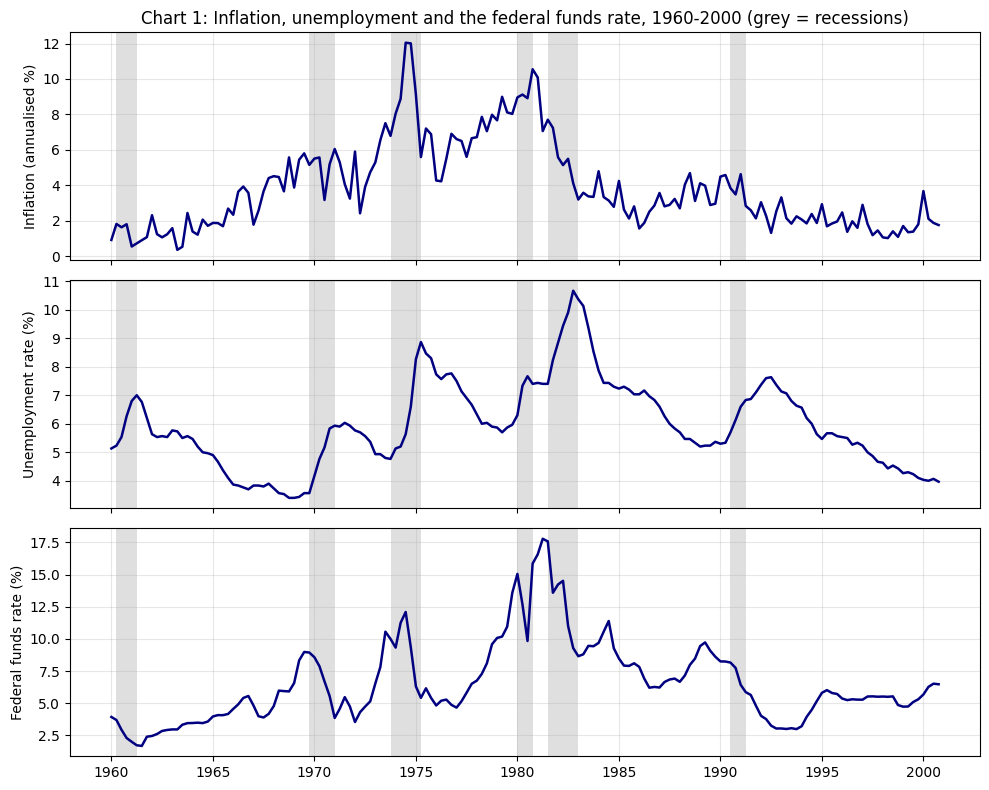

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

x = df.index.to_timestamp()

recessions = [("1960Q2","1961Q1"), ("1969Q4","1970Q4"), ("1973Q4","1975Q1"),
              ("1980Q1","1980Q3"), ("1981Q3","1982Q4"), ("1990Q3","1991Q1")]

def shade(ax):
    for a, b in recessions:
        ax.axvspan(pd.Period(a).to_timestamp(), pd.Period(b).to_timestamp(how="end"),
                   color="grey", alpha=0.25, lw=0)

# Chart 1: the three series, recessions shaded
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
labels = ["Inflation (annualised %)", "Unemployment rate (%)", "Federal funds rate (%)"]
for ax, c, lab in zip(axes, names, labels):
    ax.plot(x, df[c], color="navy", lw=1.8)
    shade(ax); ax.set_ylabel(lab); ax.grid(alpha=0.3)
axes[0].set_title("Chart 1: Inflation, unemployment and the federal funds rate, 1960-2000 (grey = recessions)")
plt.tight_layout(); plt.show()

The three time series reveal substantial changes in U.S. macroeconomic conditions over the sample period. Inflation increased throughout the late 1960s and peaked during the 1970s, reaching approximately 12% in 1974, before rising again around 1980. Unemployment also increased during recessions, reaching approximately 11% in the early 1980s. The federal funds rate rose sharply during this period, peaking at approximately 18% in 1981 as the Federal Reserve tightened monetary policy to combat high inflation.

Following the early 1980s, inflation declined substantially, while unemployment gradually fell as the economy recovered. The grey shaded regions identify recessions, illustrating how economic downturns are associated with increases in unemployment and, in some episodes, sharp changes in inflation and interest rates.

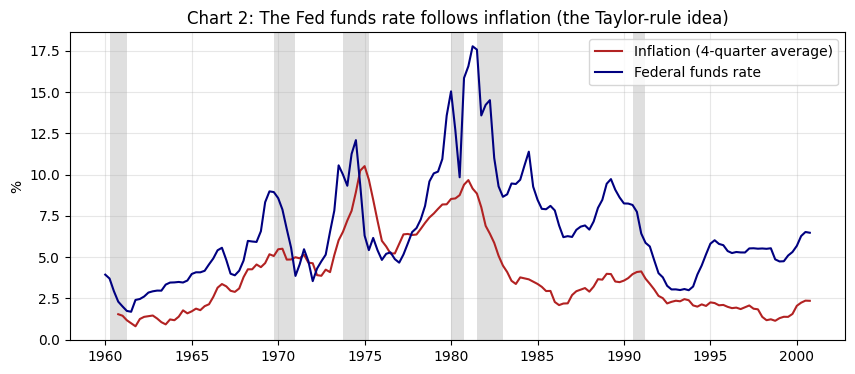

In [ ]:
# Chart 2: smoothed inflation vs fed funds
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, df["inflation"].rolling(4).mean(), label="Inflation (4-quarter average)", color="firebrick")
ax.plot(x, df["fedfunds"], label="Federal funds rate", color="navy")
shade(ax); ax.legend(); ax.grid(alpha=0.3); ax.set_ylabel("%")
ax.set_title("Chart 2: The Fed funds rate follows inflation (the Taylor-rule idea)")
plt.show()


This chart compares the federal funds rate with the four-quarter average of inflation to illustrate the relationship between monetary policy and price developments. The federal funds rate generally moves in the same direction as inflation, although the timing and magnitude of the movements differ. This is particularly evident during the 1970s and early 1980s, when rising inflation was accompanied by substantial increases in interest rates.

The sharp increase in the federal funds rate around 1979–1981 reflects the Federal Reserve's aggressive monetary tightening under Paul Volcker. Interest rates subsequently remained high as inflation declined, indicating that monetary policy continued to be restrictive even after inflation began falling. This pattern illustrates the Taylor-rule idea that central banks systematically adjust interest rates in response to inflation, although the chart alone does not establish a causal relationship or identify the precise policy rule.


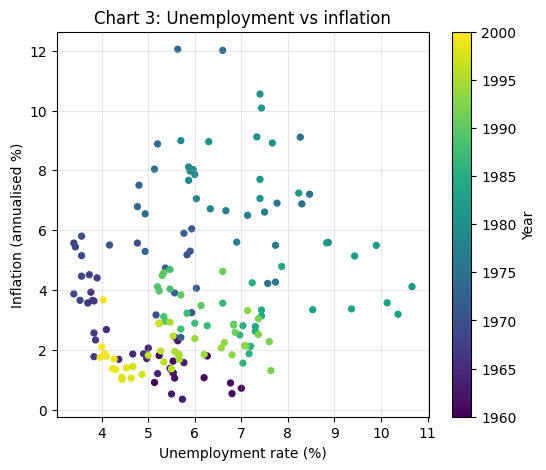

In [ ]:
# Chart 3: Phillips-curve scatter, coloured by decade
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(df["unemployment"], df["inflation"], c=df.index.year, cmap="viridis", s=18)
plt.colorbar(sc, label="Year")
ax.set_xlabel("Unemployment rate (%)"); ax.set_ylabel("Inflation (annualised %)")
ax.set_title("Chart 3: Unemployment vs inflation"); ax.grid(alpha=0.3)
plt.show()


This scatter plot examines the relationship between unemployment and inflation, with each observation representing a quarter and its colour indicating the year. The distribution does not reveal a simple, stable negative relationship between the two variables. Instead, the observations form different patterns across periods, suggesting that the inflation-unemployment relationship changes over time.

The 1970s are particularly notable because several observations combine relatively high inflation with elevated unemployment, illustrating the phenomenon of stagflation. This challenges the idea of a stable short-run Phillips curve in which higher inflation is consistently associated with lower unemployment. The variation across years suggests that the relationship depends on changing macroeconomic conditions and economic shocks.

### Correlation of Reduced-Form VAR Residuals

The reduced-form VAR allows unexpected movements in inflation, unemployment and the federal funds rate to be contemporaneously correlated. This heatmap displays the pairwise correlations between the estimated residuals from the three VAR equations.

Non-zero correlations indicate that shocks across equations are not independent within the same quarter.

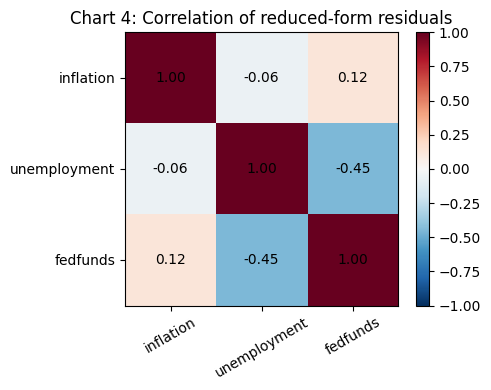

In [ ]:
# Chart 4: why we need Cholesky: VAR residuals are correlated
resid_corr = pd.DataFrame(res.resid, columns=names).corr()
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(resid_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(names, rotation=30)
ax.set_yticks(range(3)); ax.set_yticklabels(names)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{resid_corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im); ax.set_title("Chart 4: Correlation of reduced-form residuals")
plt.tight_layout(); plt.show()


### Stationarity Diagnostics: Augmented Dickey-Fuller Test

Before proceeding with the VAR analysis, this step examines whether inflation, unemployment and the federal funds rate are stationary using the Augmented Dickey-Fuller (ADF) test. A stationary time series has statistical properties, such as its mean and variance, that remain constant over time.

The ADF test evaluates the null hypothesis that a series contains a unit root and is therefore non-stationary:

$$
H_0: \text{The series contains a unit root}
$$

$$
H_1: \text{The series is stationary}
$$

The test includes a constant (`regression="c"`) and selects the number of additional lagged differences using the Akaike Information Criterion (AIC). These tests are diagnostic only: the original Stock and Watson specification is estimated in levels, so the variables are not differenced.

In [ ]:
adf = {}

for c in names:
    result = adfuller(df[c], regression="c", autolag="AIC", result_object = False)
    adf[c] = {
        "ADF stat": result[0],
        "p-value": result[1]
    }

adf = pd.DataFrame(adf).T
print(adf.round(3))

              ADF stat  p-value
inflation       -1.912    0.327
unemployment    -2.823    0.055
fedfunds        -2.405    0.140


### Interpretation

The ADF test results provide limited evidence that the three variables are stationary. Inflation has a p-value of 0.327, while the federal funds rate has a p-value of 0.140. Since both exceed the 5% significance level, we fail to reject the null hypothesis of a unit root for either series. Unemployment has a p-value of 0.055, which is close to the 5% threshold but still insufficient to reject the null hypothesis at that level.

These results suggest that non-stationarity may be a concern, particularly for inflation and the federal funds rate. However, failure to reject the null hypothesis does not prove that a series contains a unit root. We retain all three variables in levels to follow the specification used in this replication of Stock and Watson (2001), rather than automatically differencing them based on these diagnostic tests.

### Impulse Response Functions (IRFs) — Stock and Watson Figure 1

This step estimates and plots orthogonalised impulse response functions (IRFs) to examine how unexpected shocks to inflation, unemployment and the federal funds rate affect all three variables over the following 24 quarters. An IRF traces the dynamic response of each variable to a one-time shock, holding the VAR's estimated dynamics constant.

The reduced-form VAR innovations may be contemporaneously correlated, meaning an unexpected movement in one equation can coincide with unexpected movements in the others. To identify separate shocks, we apply a Cholesky decomposition to the estimated residual covariance matrix:

$$
\Sigma_u = PP'
$$

The resulting orthogonalised shocks are uncorrelated, but their identification depends on the recursive ordering of the variables: inflation, unemployment and the federal funds rate. This ordering imposes the assumption that inflation does not respond contemporaneously to unemployment or the federal funds rate, unemployment can respond contemporaneously to inflation, and the federal funds rate can respond contemporaneously to both inflation and unemployment.

The impulse responses are normalised so that each shock represents a one-standard-deviation impact on its corresponding variable. This makes the responses comparable across shocks. The resulting 3 × 3 figure displays each shock in a separate row and each responding variable in a separate column, with responses traced over 24 quarters.

The figure includes two measures of uncertainty. The shaded bands represent asymptotic confidence intervals of approximately one standard error above and below the estimated response. The red dashed lines represent Monte Carlo confidence bands based on 1,000 simulations, using a 68% confidence level. Comparing these intervals helps assess the precision of the estimated responses. If a confidence interval includes zero, the corresponding response is not statistically distinguishable from zero at that confidence level.

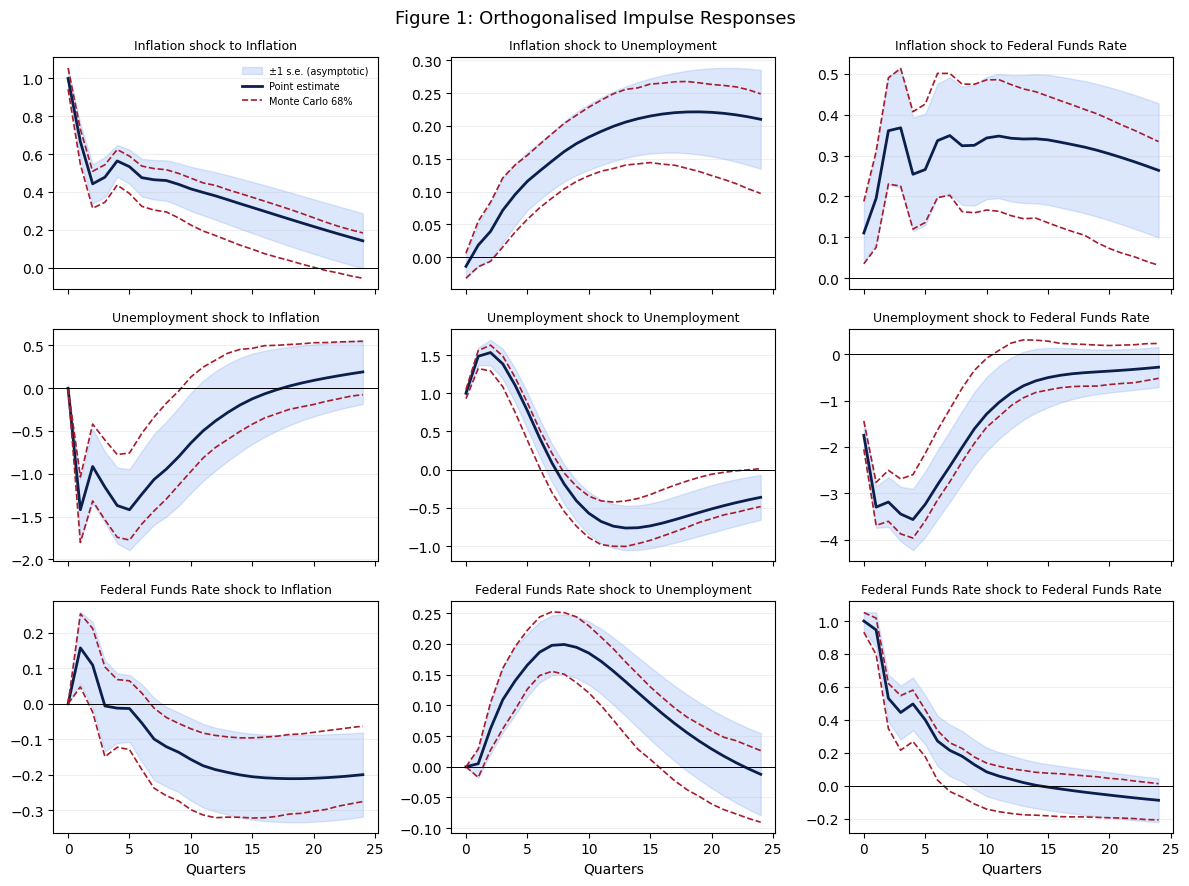

Mean asymptotic band width: 0.433
Mean Monte Carlo band width: 0.413


In [ ]:
P = np.linalg.cholesky(res.sigma_u)
assert np.allclose(P @ P.T, res.sigma_u)      # Cholesky check
scale = np.diag(P)

irf = res.irf(24)
point = irf.orth_irfs / scale
se = irf.stderr(orth=True) / scale
lower_a, upper_a = point - se, point + se

lower, upper = irf.errband_mc(orth=True, repl=1000, signif=0.32,
                              rng=np.random.RandomState(42))
lower, upper = lower / scale, upper / scale

titles = ["Inflation", "Unemployment", "Federal Funds Rate"]
q = range(25)
fig, axes = plt.subplots(3, 3, figsize=(12, 9), sharex=True)

for shock in range(3):
    for resp in range(3):
        ax = axes[shock, resp]
        ax.fill_between(q, lower_a[:, resp, shock], upper_a[:, resp, shock],
                        color="#6495ED", alpha=0.22, label="±1 s.e. (asymptotic)")
        ax.plot(q, point[:, resp, shock], color="#0B1F4D", lw=2, label="Point estimate")
        ax.plot(q, lower[:, resp, shock], color="#A61C2D", ls="--", lw=1.2, label="Monte Carlo 68%")
        ax.plot(q, upper[:, resp, shock], color="#A61C2D", ls="--", lw=1.2)
        ax.axhline(0, color="black", lw=0.7)
        ax.set_title(f"{titles[shock]} shock to {titles[resp]}", fontsize=9)
        ax.grid(axis="y", alpha=0.2)
        if shock == 2:
            ax.set_xlabel("Quarters")

axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Figure 1: Orthogonalised Impulse Responses", fontsize=13)
plt.tight_layout()
plt.show()

print("Mean asymptotic band width:", round((upper_a - lower_a).mean(), 3))
print("Mean Monte Carlo band width:", round((upper - lower).mean(), 3))

### Forecast Error Variance Decomposition (FEVD) — Stock and Watson Table 1.B

Forecast error variance decomposition measures how much of the uncertainty in a variable's future forecasts can be attributed to shocks in each variable. Using the estimated recursive VAR(4), this step calculates the forecast error standard errors and the percentage contribution of inflation, unemployment and federal funds rate shocks at horizons of 1, 4, 8 and 12 quarters.

The decomposition relies on the Cholesky identification scheme and the ordering of inflation, unemployment and the federal funds rate. The contribution of each shock is expressed as a percentage, with the three contributions summing to 100% at every forecast horizon. The resulting estimates are compared with Stock and Watson's published Table 1.B to assess how closely the replication matches the original results.

In [ ]:
fe = res.fevd(12)
mse = res.mse(12)                       # forecast-error variance matrices, shape (12, 3, 3)

rows = []
for i, v in enumerate(names):
    for h in [1, 4, 8, 12]:
        shares = fe.decomp[i, h - 1, :] * 100
        rows.append([v, h, np.sqrt(mse[h - 1][i, i]), *shares])
mine_1b = pd.DataFrame(rows, columns=["variable", "h", "SE", "pi shock", "u shock", "R shock"])

# Every row must sum to 100
assert np.allclose(mine_1b[["pi shock", "u shock", "R shock"]].sum(axis=1), 100)

# Published Table 1.B
pub = [
    ("inflation",    1, 0.96, 100,  0,  0), ("inflation",    4, 1.34, 88, 10,  2),
    ("inflation",    8, 1.75,  82, 17,  1), ("inflation",   12, 1.97, 82, 16,  2),
    ("unemployment", 1, 0.23,   1, 99,  0), ("unemployment", 4, 0.64,  0, 98,  2),
    ("unemployment", 8, 0.79,   7, 82, 11), ("unemployment",12, 0.92, 16, 66, 18),
    ("fedfunds",     1, 0.85,   2, 19, 79), ("fedfunds",     4, 1.84,  9, 50, 41),
    ("fedfunds",     8, 2.44,  12, 60, 28), ("fedfunds",    12, 2.63, 16, 59, 25),
]
pub_1b = pd.DataFrame(pub, columns=mine_1b.columns)

diff = mine_1b.copy()
diff.iloc[:, 2:] = mine_1b.iloc[:, 2:].values - pub_1b.iloc[:, 2:].values

print("Mine:");      print(mine_1b.round(2).to_string(index=False))
print("\nDifference (mine - published):"); print(diff.round(2).to_string(index=False))

Mine:
    variable  h   SE  pi shock  u shock  R shock
   inflation  1 0.99    100.00     0.00     0.00
   inflation  4 1.43     88.45    10.44     1.11
   inflation  8 1.85     82.96    16.13     0.90
   inflation 12 2.07     82.58    15.43     1.99
unemployment  1 0.23      0.35    99.65     0.00
unemployment  4 0.63      1.76    95.79     2.44
unemployment  8 0.80     10.47    76.26    13.27
unemployment 12 0.95     21.12    59.74    19.14
    fedfunds  1 0.88      1.52    19.94    78.54
    fedfunds  4 1.90      8.51    50.99    40.51
    fedfunds  8 2.48     10.78    60.34    28.87
    fedfunds 12 2.67     15.46    59.01    25.53

Difference (mine - published):
    variable  h    SE  pi shock  u shock  R shock
   inflation  1  0.03      0.00     0.00     0.00
   inflation  4  0.09      0.45     0.44    -0.89
   inflation  8  0.10      0.96    -0.87    -0.10
   inflation 12  0.10      0.58    -0.57    -0.01
unemployment  1 -0.00     -0.65     0.65     0.00
unemployment  4 -0.01    

### Interpretation

The results show that each variable's forecast uncertainty is initially dominated by its own shocks. At the one-quarter horizon, inflation shocks explain 100% of inflation forecast error variance, unemployment shocks explain approximately 100% of unemployment forecast error variance, and federal funds rate shocks explain approximately 79% of federal funds rate forecast error variance.

As the forecast horizon increases, shocks from other variables become more important. For unemployment, the contribution of its own shocks falls from approximately 100% at one quarter to 60% at twelve quarters, while inflation and federal funds rate shocks jointly account for a larger share. Similarly, inflation shocks explain an increasing share of federal funds rate forecast uncertainty over the first eight quarters.

The replicated estimates are generally close to the published results. The largest differences appear in the twelve-quarter decomposition of unemployment, where inflation shocks explain approximately 21% of forecast error variance in the replication, compared with 16% in the original table.

### Out-of-Sample Forecasting — Stock and Watson Table 2

This section evaluates whether the VAR(4) provides more accurate forecasts than simpler alternatives. Three forecasting models are considered: a random walk (RW), which assumes that future values remain at their latest observed levels; univariate autoregressive models (AR), which use the past values of each variable independently; and the multivariate VAR(4), which incorporates the lagged values of all three variables.

Forecasts are generated recursively using an expanding estimation window. For each target quarter between 1985Q1 and 2000Q4, the models are estimated using only observations available before the forecast origin. Forecast accuracy is evaluated at 2-, 4- and 8-quarter horizons using the root mean squared forecast error (RMSE).

Inflation is evaluated using its average over the forecast horizon, while unemployment and the federal funds rate are evaluated using their values at the end of the horizon.

In [ ]:
from statsmodels.tsa.ar_model import AutoReg

horizons = [2, 4, 8]
RW_INFLATION = "last"          # try "last" (latest quarter) and "avg4" (last 4-quarter average)
first_target, last_target = pd.Period("1985Q1"), pd.Period("2000Q4")

def target_value(h, origin):
    """Actual outcomes: average inflation over the next h quarters; u and R at quarter origin+h."""
    window = df.iloc[origin + 1: origin + h + 1]
    return np.array([window["inflation"].mean(), window["unemployment"].iloc[-1], window["fedfunds"].iloc[-1]])

def make_forecasts(h, origin):
    train = df.iloc[: origin + 1]
    out = {}

    # VAR(4): iterate forward h steps, then average inflation
    var_fit = VAR(train).fit(4, trend="c")
    f = var_fit.forecast(train.values[-4:], steps=h)
    out["VAR"] = np.array([f[:, 0].mean(), f[-1, 1], f[-1, 2]])

    # Univariate AR(4) for each variable
    ar = []
    for c in names:
        path = AutoReg(train[c].values, lags=4, trend="c").fit().predict(start=len(train), end=len(train) + h - 1)
        ar.append(path.mean() if c == "inflation" else path[-1])
    out["AR"] = np.array(ar)

    # Random walk ("no change")
    infl_rw = train["inflation"].iloc[-1] if RW_INFLATION == "last" else train["inflation"].iloc[-4:].mean()
    out["RW"] = np.array([infl_rw, train["unemployment"].iloc[-1], train["fedfunds"].iloc[-1]])
    return out

results = []
for h in horizons:
    errors = {m: [] for m in ["RW", "AR", "VAR"]}
    for target in pd.period_range(first_target, last_target, freq="Q"):
        origin = df.index.get_loc(target) - h
        actual = target_value(h, origin)
        fc = make_forecasts(h, origin)
        for m in errors:
            errors[m].append(fc[m] - actual)
    n_fc = len(errors["VAR"])
    for j, v in enumerate(names):
        row = {"variable": v, "h": h, "n": n_fc}
        for m in ["RW", "AR", "VAR"]:
            row[m] = np.sqrt(np.mean(np.array(errors[m])[:, j] ** 2))
        results.append(row)

table2 = pd.DataFrame(results)
print(table2.round(2).to_string(index=False))

    variable  h  n   RW   AR  VAR
   inflation  2 64 0.80 0.70 0.69
unemployment  2 64 0.34 0.28 0.29
    fedfunds  2 64 0.88 0.84 0.70
   inflation  4 64 0.72 0.68 0.67
unemployment  4 64 0.60 0.52 0.52
    fedfunds  4 64 1.44 1.32 1.17
   inflation  8 64 0.76 0.83 0.84
unemployment  8 64 1.22 0.92 0.83
    fedfunds  8 64 2.25 1.96 1.71


### Forecast Evaluation — Stock and Watson Table 2 continued

This step compares the out-of-sample forecasting performance of three models: a random walk (RW), separate univariate autoregressive models (AR), and the multivariate VAR(4). Forecasts are evaluated at horizons of 2, 4 and 8 quarters over the period 1985Q1–2000Q4.

Performance is measured using the root mean squared forecast error (RMSE), which calculates the typical magnitude of forecast errors while placing greater weight on larger errors. Lower RMSE indicates greater forecasting accuracy.


In [ ]:
# Published Table 2
pub2 = pd.DataFrame({
    "h": [2, 4, 8] * 3,
    "variable": ["inflation"] * 3 + ["unemployment"] * 3 + ["fedfunds"] * 3,
    "RW":  [0.82, 0.73, 0.75, 0.34, 0.62, 1.12, 0.79, 1.36, 2.18],
    "AR":  [0.70, 0.65, 0.75, 0.28, 0.52, 0.95, 0.77, 1.25, 1.92],
    "VAR": [0.68, 0.63, 0.75, 0.29, 0.53, 0.78, 0.68, 1.07, 1.70],
})

# Replicated vs published, side by side
cmp = table2.merge(pub2, on=["variable", "h"], suffixes=("_mine", "_pub"))
for m in ["RW", "AR", "VAR"]:
    cmp[f"{m}_diff"] = cmp[f"{m}_mine"] - cmp[f"{m}_pub"]
cols = ["variable", "h", "n"] + [f"{m}_{s}" for m in ["RW", "AR", "VAR"] for s in ["mine", "pub", "diff"]]
print(cmp[cols].round(2).to_string(index=False))

# Which random-walk definition for inflation matches the paper?
def rw_rmse(h, how):
    errs = []
    for target in pd.period_range(first_target, last_target, freq="Q"):
        origin = df.index.get_loc(target) - h
        actual = target_value(h, origin)
        infl = df["inflation"].iloc[origin] if how == "last" else df["inflation"].iloc[origin - 3: origin + 1].mean()
        fc = np.array([infl, df["unemployment"].iloc[origin], df["fedfunds"].iloc[origin]])
        errs.append(fc - actual)
    return np.sqrt(np.mean(np.array(errs) ** 2, axis=0))

rw_check = pd.DataFrame({
    "h": horizons,
    "RW infl (last)": [rw_rmse(h, "last")[0] for h in horizons],
    "RW infl (avg4)": [rw_rmse(h, "avg4")[0] for h in horizons],
    "published": pub2[pub2.variable == "inflation"]["RW"].values,
})
print(rw_check.round(2).to_string(index=False))

# Does the paper's qualitative conclusion hold? VAR <= AR <= RW
cmp["VAR_beats_AR"] = cmp["VAR_mine"] <= cmp["AR_mine"]
cmp["AR_beats_RW"]  = cmp["AR_mine"]  <= cmp["RW_mine"]
print(cmp[["variable", "h", "VAR_beats_AR", "AR_beats_RW"]].to_string(index=False))

    variable  h  n  RW_mine  RW_pub  RW_diff  AR_mine  AR_pub  AR_diff  VAR_mine  VAR_pub  VAR_diff
   inflation  2 64     0.80    0.82    -0.02     0.70    0.70    -0.00      0.69     0.68      0.01
unemployment  2 64     0.34    0.34    -0.00     0.28    0.28    -0.00      0.29     0.29      0.00
    fedfunds  2 64     0.88    0.79     0.09     0.84    0.77     0.07      0.70     0.68      0.02
   inflation  4 64     0.72    0.73    -0.01     0.68    0.65     0.03      0.67     0.63      0.04
unemployment  4 64     0.60    0.62    -0.02     0.52    0.52     0.00      0.52     0.53     -0.01
    fedfunds  4 64     1.44    1.36     0.08     1.32    1.25     0.07      1.17     1.07      0.10
   inflation  8 64     0.76    0.75     0.01     0.83    0.75     0.08      0.84     0.75      0.09
unemployment  8 64     1.22    1.12     0.10     0.92    0.95    -0.03      0.83     0.78      0.05
    fedfunds  8 64     2.25    2.18     0.07     1.96    1.92     0.04      1.71     1.70      0.01


### Interpretation

The replicated results are generally close to Stock and Watson's published estimates. The random-walk inflation specification using the latest quarterly observation produces RMSEs of 0.80, 0.72 and 0.76 at the 2-, 4- and 8-quarter horizons, closely matching the published values. Using the previous four-quarter average produces substantially different results, indicating that the latest observation is the closer match to the paper's specification.

The VAR generally delivers the lowest forecast errors, particularly for the federal funds rate, where it outperforms both the AR and random-walk models at all three forecast horizons. For unemployment, however, the AR model slightly outperforms the VAR at the 2- and 4-quarter horizons. At the 8-quarter horizon, the VAR performs best for unemployment.

The results therefore provide broad, but not universal, support for the paper's finding that multivariate VAR models can improve forecasting performance by incorporating information from the other variables. The advantage depends on the variable being forecast and the forecast horizon. In particular, the VAR does not consistently outperform the simpler alternatives for inflation at longer horizons.


## Figure 2: Impulse responses to a monetary policy shock under two Taylor-rule identifications

This figure plots the responses of inflation, unemployment and the real interest rate to a monetary policy shock, scaled so that the federal funds rate rises by exactly 1 percentage point on impact. The solid line assumes a backward-looking Taylor rule, where the Fed reacts to average inflation and unemployment over the past four quarters. The dashed line assumes a forward-looking rule, where the Fed reacts to four-quarter-ahead VAR forecasts of both variables.

To construct it, I define the Taylor-rule variable ra = R − fp·π − fu·u and estimate a VAR(4) with a constant on (ra, π, u), ordering ra first so that the policy shock is the first Cholesky shock. For the forward-looking rule, the weights come from the four-quarter-ahead forecast coefficients of my own reduced-form VAR, following the authors' comp.gss, and the real rate is R − π. These coefficients (pp, pu, pr = 0.516, −1.107, 0.062; up, uu, ur = 0.068, 1.515, 0.079) are close to the authors' (0.478, −0.984, 0.086; 0.047, 1.500, 0.071), which is what small data differences would produce.

pp pu pr: [ 0.516 -1.107  0.062] | up uu ur: [0.068 1.515 0.079]


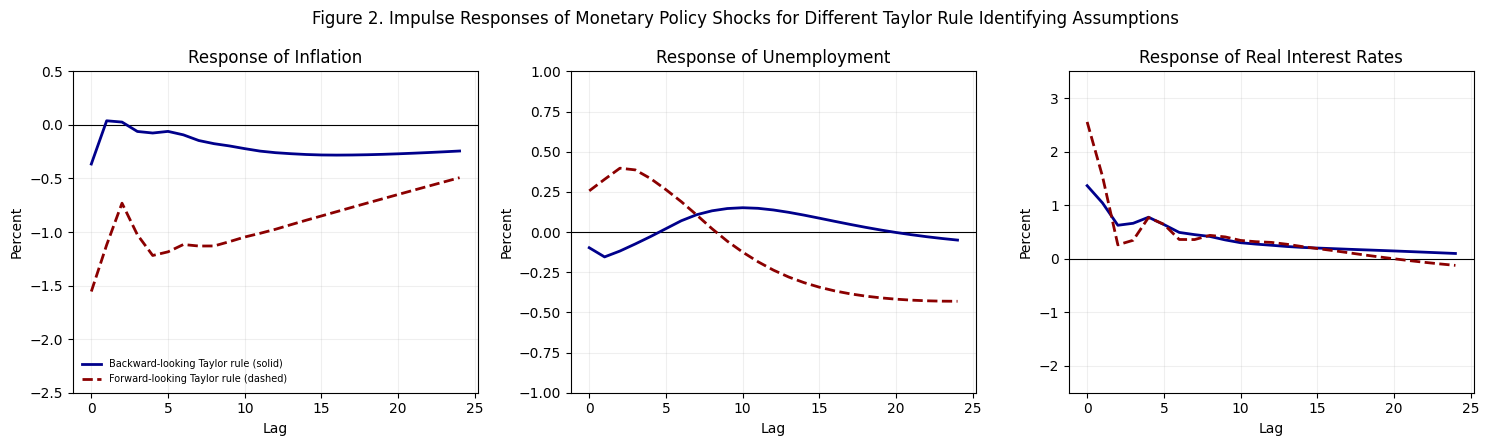

Inflation at lag 0 -> backward: -0.365 | forward: -1.555


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR

# Weights of the Taylor rule: ra = R - fp*inflation - fu*unemployment
def weights(kind):
    if kind == "backward":
        return 1.5 / 4, -1.25 / 4

    # Forward: coefficients of the 4-quarter-ahead forecast (average over next 4 quarters)
    A = np.zeros((12, 12))                    # companion matrix of the VAR(4)
    A[:3, :] = np.hstack(res.coefs)
    A[3:, :-3] = np.eye(9)
    F = np.linalg.matrix_power(A, 4)
    avg = lambda i: sum(F[3 * j + i, :3] for j in range(4)) / 4
    pp, pu, pr = avg(0)                       # inflation forecast on current (pi, u, R)
    up, uu, ur = avg(1)                       # unemployment forecast on current (pi, u, R)
    print("pp pu pr:", np.round([pp, pu, pr], 3), "| up uu ur:", np.round([up, uu, ur], 3))

    fp1, fu1 = 1.5, -1.25
    fr2 = fp1 * pr + fu1 * ur
    return (fp1 * pp + fu1 * up) / (1 - fr2), (fp1 * pu + fu1 * uu) / (1 - fr2)

# Responses to the policy shock, scaled so the funds rate rises 1 pp on impact
def policy_irf(df, fp, fu):
    Y = pd.DataFrame({"ra": df["fedfunds"] - fp * df["inflation"] - fu * df["unemployment"],
                      "p": df["inflation"], "u": df["unemployment"]})
    out = VAR(Y).fit(4, trend="c").irf(24).orth_irfs[:, :, 0]   # first shock = policy shock
    ra, p, u = out.T
    r = ra + fp * p + fu * u                                     # funds-rate response
    return {"infl": p / r[0], "unemp": u / r[0], "real": (r - p) / r[0]}

back = policy_irf(df, *weights("backward"))
fwd = policy_irf(df, *weights("forward"))

# Figure 2
panels = [("infl", "Response of Inflation", (-2.5, 0.5)),
          ("unemp", "Response of Unemployment", (-1, 1)),
          ("real", "Response of Real Interest Rates", (-2.5, 3.5))]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (key, title, ylim) in zip(axes, panels):
    ax.axhline(0, color="black", lw=0.8)
    ax.plot(back[key], color="darkblue", lw=2, label="Backward-looking Taylor rule (solid)")
    ax.plot(fwd[key], color="darkred", lw=2, ls="--", label="Forward-looking Taylor rule (dashed)")
    ax.set_ylim(ylim); ax.set_title(title)
    ax.set_xlabel("Lag"); ax.set_ylabel("Percent"); ax.grid(alpha=0.2)
axes[0].legend(fontsize=7, frameon=False, loc="lower left")
fig.suptitle("Figure 2. Impulse Responses of Monetary Policy Shocks for Different Taylor Rule Identifying Assumptions")
plt.tight_layout()
fig.savefig("/content/drive/MyDrive/Stock_Watson_VAR/outputs/figures/figure2_replicated.png", dpi=150, bbox_inches="tight")
plt.show()

# Lag-0 check against the authors' figure.gss values (backward: -0.372, forward: -1.647)
print("Inflation at lag 0 -> backward:", round(back["infl"][0], 3), "| forward:", round(fwd["infl"][0], 3))

Under both rules the policy shock raises the real interest rate on impact, and the two real-rate paths are broadly similar, as in the paper. The rules differ sharply in their implications for the rest of the economy. The backward-looking rule implies a modest fall in inflation and a mild rise in unemployment, mostly several years out, while the forward-looking rule implies a much faster and larger rise in unemployment and a larger decline in inflation. The same 1 percentage point rate hike therefore looks like a mild slowdown under one assumption and a sharp recession under the other, which shows that structural conclusions depend heavily on the assumed policy rule.

As a replication check, the inflation response at lag 0 is −0.365 under the backward rule and −1.555 under the forward rule, against the authors' −0.372 and −1.647. The shapes match, and the remaining gaps most likely reflect data differences and the 1960Q1 sample start, where the first four observations serve as lags. No confidence bands are shown because the original figure has none. These responses are identified under an assumed policy rule, so they should not be read as proven causal effects.

## Conclusion

This project replicated Tables 1.A, 1.B and 2 and Figures 1 and 2 of Stock and Watson (2001) from the original quarterly data. Most entries reproduce closely: the Granger-causality p-values are within about 0.02 of the paper except for the federal funds rate in the inflation equation (0.65 against 0.27); the variance decompositions for inflation and the funds rate are within about one percentage point; the forecast RMSEs are mostly within 0.05 to 0.10; and the impulse responses in both figures match the published shapes. The largest gaps are in the unemployment variance decomposition at long horizons (up to about six percentage points) and in the h = 8 inflation forecasts, where the AR and VAR RMSEs are 0.83 and 0.84 against 0.75.

Substantively, the results support the paper's central message. The reduced-form VAR describes the comovement of inflation, unemployment and the funds rate well and gives forecasts that beat a random walk, but Figure 2 shows that the estimated effect of a policy shock depends heavily on the assumed Taylor rule: the same 1 percentage point rate hike implies a mild slowdown under the backward-looking rule and a sharp recession under the forward-looking one. The data alone cannot choose between them. The identification also rests on a small, constant-coefficient system, which the paper criticises for omitted variables, parameter instability and timing assumptions.